# **01. Exploratory Data Analysis (EDA) & Integrity Audit**

### **Real-Time American Sign Language (ASL) Fingerspelling Recognition**

**Course**: Deep Learning Midterm Project — Supervised by **Dr. Ngan**  
**Dataset**: Kaggle ASL Alphabet (grassknoted)  
**Scale**: 87,000 RGB images ($200 \times 200 \text{ px}$), 29 discrete classes ($3,000 \text{ images/class}$)  
**Core Objectives**:
1. Audit dataset integrity, image format uniformity ($200 \times 200$ RGB), and exact class balance.
2. Characterize luminance and background distributions across classes to evaluate shortcut learning risks.
3. Quantify intra-class temporal redundancy (near-duplicate frames) to establish valid generalization baselines.
4. Document fine-grained morphological ambiguities (e.g., the fist tuck triplet `M` vs `N` vs `S`) to motivate the 3-model progression.

**Cell 2: Imports, Paths, and Deterministic Setup**

In [16]:
import os
import re
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Global reproducibility setup
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

# Directory paths (relative to notebooks/)
DATA_DIR = Path("../data/raw/asl_alphabet_train")
OUTPUT_FIGS = Path("../docs/figures")
SPLITS_DIR = Path("../data/splits")
DOCS_DIR = Path("../docs")

OUTPUT_FIGS.mkdir(parents=True, exist_ok=True)

# Discover and sort class directories
CLASSES = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
assert len(CLASSES) == 29, f"Expected 29 class folders, found {len(CLASSES)}"
print(f"[OK] Discovered {len(CLASSES)} classes: {CLASSES}")

[OK] Discovered 29 classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


**Cell 3 [Code]: Integrity Audit & Image Specification Verification**

In [17]:
# Cell 3: Fast Integrity & Metadata Verification
print("=" * 60)
print("VERIFYING DATASET INTEGRITY & IMAGE METADATA")
print("=" * 60)

# Check total files and class balance
class_file_map = {cls_name: sorted((DATA_DIR / cls_name).glob("*.jpg")) for cls_name in CLASSES}
total_files = sum(len(files) for files in class_file_map.values())

print(f"Total images found: {total_files:,} (Target: 87,000)")
assert total_files == 87000, f"Expected 87,000 total images, found {total_files}"

# Sample-based metadata check (Verifies 10 random images per class = 290 images)
rng = random.Random(GLOBAL_SEED)
corrupt_count = 0
invalid_dims = 0
invalid_modes = 0

for cls_name, files in class_file_map.items():
    assert len(files) == 3000, f"Class '{cls_name}' count mismatch: {len(files)} != 3000"
    sampled_check = rng.sample(files, 10)
    for p in sampled_check:
        if p.stat().st_size == 0:
            corrupt_count += 1
            continue
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                if im.size != (200, 200):
                    invalid_dims += 1
                if im.mode != "RGB":
                    invalid_modes += 1
        except Exception:
            corrupt_count += 1

print(f"Sampled Integrity Check (290 files):")
print(f"  - Corrupt or 0-byte files : {corrupt_count}")
print(f"  - Dimension mismatches    : {invalid_dims} (Target: 200x200)")
print(f"  - Color mode mismatches   : {invalid_modes} (Target: RGB)")
assert corrupt_count == 0 and invalid_dims == 0 and invalid_modes == 0, "Integrity verification failed!"
print("[OK] Dataset integrity and specification verified (100% compliant).")

VERIFYING DATASET INTEGRITY & IMAGE METADATA
Total images found: 87,000 (Target: 87,000)
Sampled Integrity Check (290 files):
  - Corrupt or 0-byte files : 0
  - Dimension mismatches    : 0 (Target: 200x200)
  - Color mode mismatches   : 0 (Target: RGB)
[OK] Dataset integrity and specification verified (100% compliant).


**Cell 4 [Code]: Class Balance Distribution Plot**

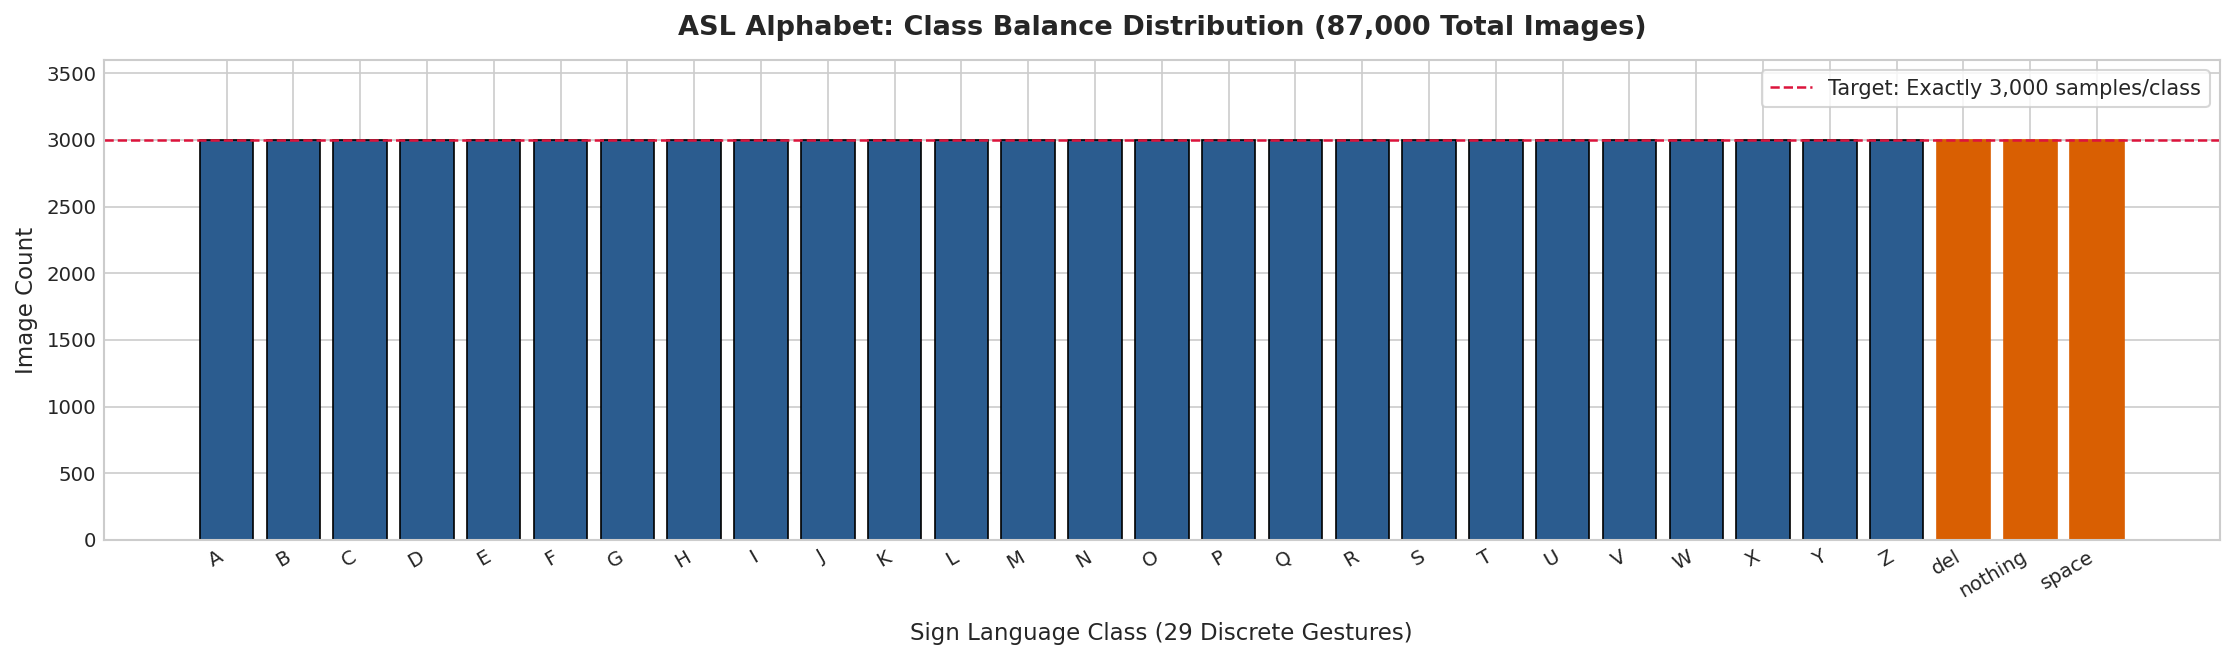

Distribution Status: All 29 classes possess exactly 3,000 samples. Total: 87,000.


In [18]:
# Cell 4: Class Balance Distribution Plot
class_counts = {cls_name: len(files) for cls_name, files in class_file_map.items()}
assert all(count == 3000 for count in class_counts.values()), "Class imbalance detected!"

df_dist = pd.DataFrame(list(class_counts.items()), columns=["Class", "Count"])

fig, ax = plt.subplots(figsize=(15, 4.5))
bars = ax.bar(df_dist["Class"], df_dist["Count"], color="#2b5c8f", edgecolor="black", linewidth=0.8)

ax.set_title("ASL Alphabet: Class Balance Distribution (87,000 Total Images)", fontsize=13, weight="bold", pad=12)
ax.set_xlabel("Sign Language Class (29 Discrete Gestures)", fontsize=11, labelpad=10)
ax.set_ylabel("Image Count", fontsize=11)
ax.set_ylim(0, 3600)
ax.axhline(3000, color="crimson", linestyle="--", linewidth=1.2, label="Target: Exactly 3,000 samples/class")

# Highlight control classes in distinct color
for idx, bar in enumerate(bars):
    if df_dist.loc[idx, "Class"] in ["del", "nothing", "space"]:
        bar.set_color("#d95f02")

ax.legend(loc="upper right", frameon=True, fontsize=10)
plt.xticks(rotation=30, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()

plt.savefig(OUTPUT_FIGS / "eda_class_distribution.png", dpi=300)
plt.show()

print(f"Distribution Status: All 29 classes possess exactly 3,000 samples. Total: {total_files:,}.")

**Cell 5: 29-Class Visual Mosaic Grid (5×6)**

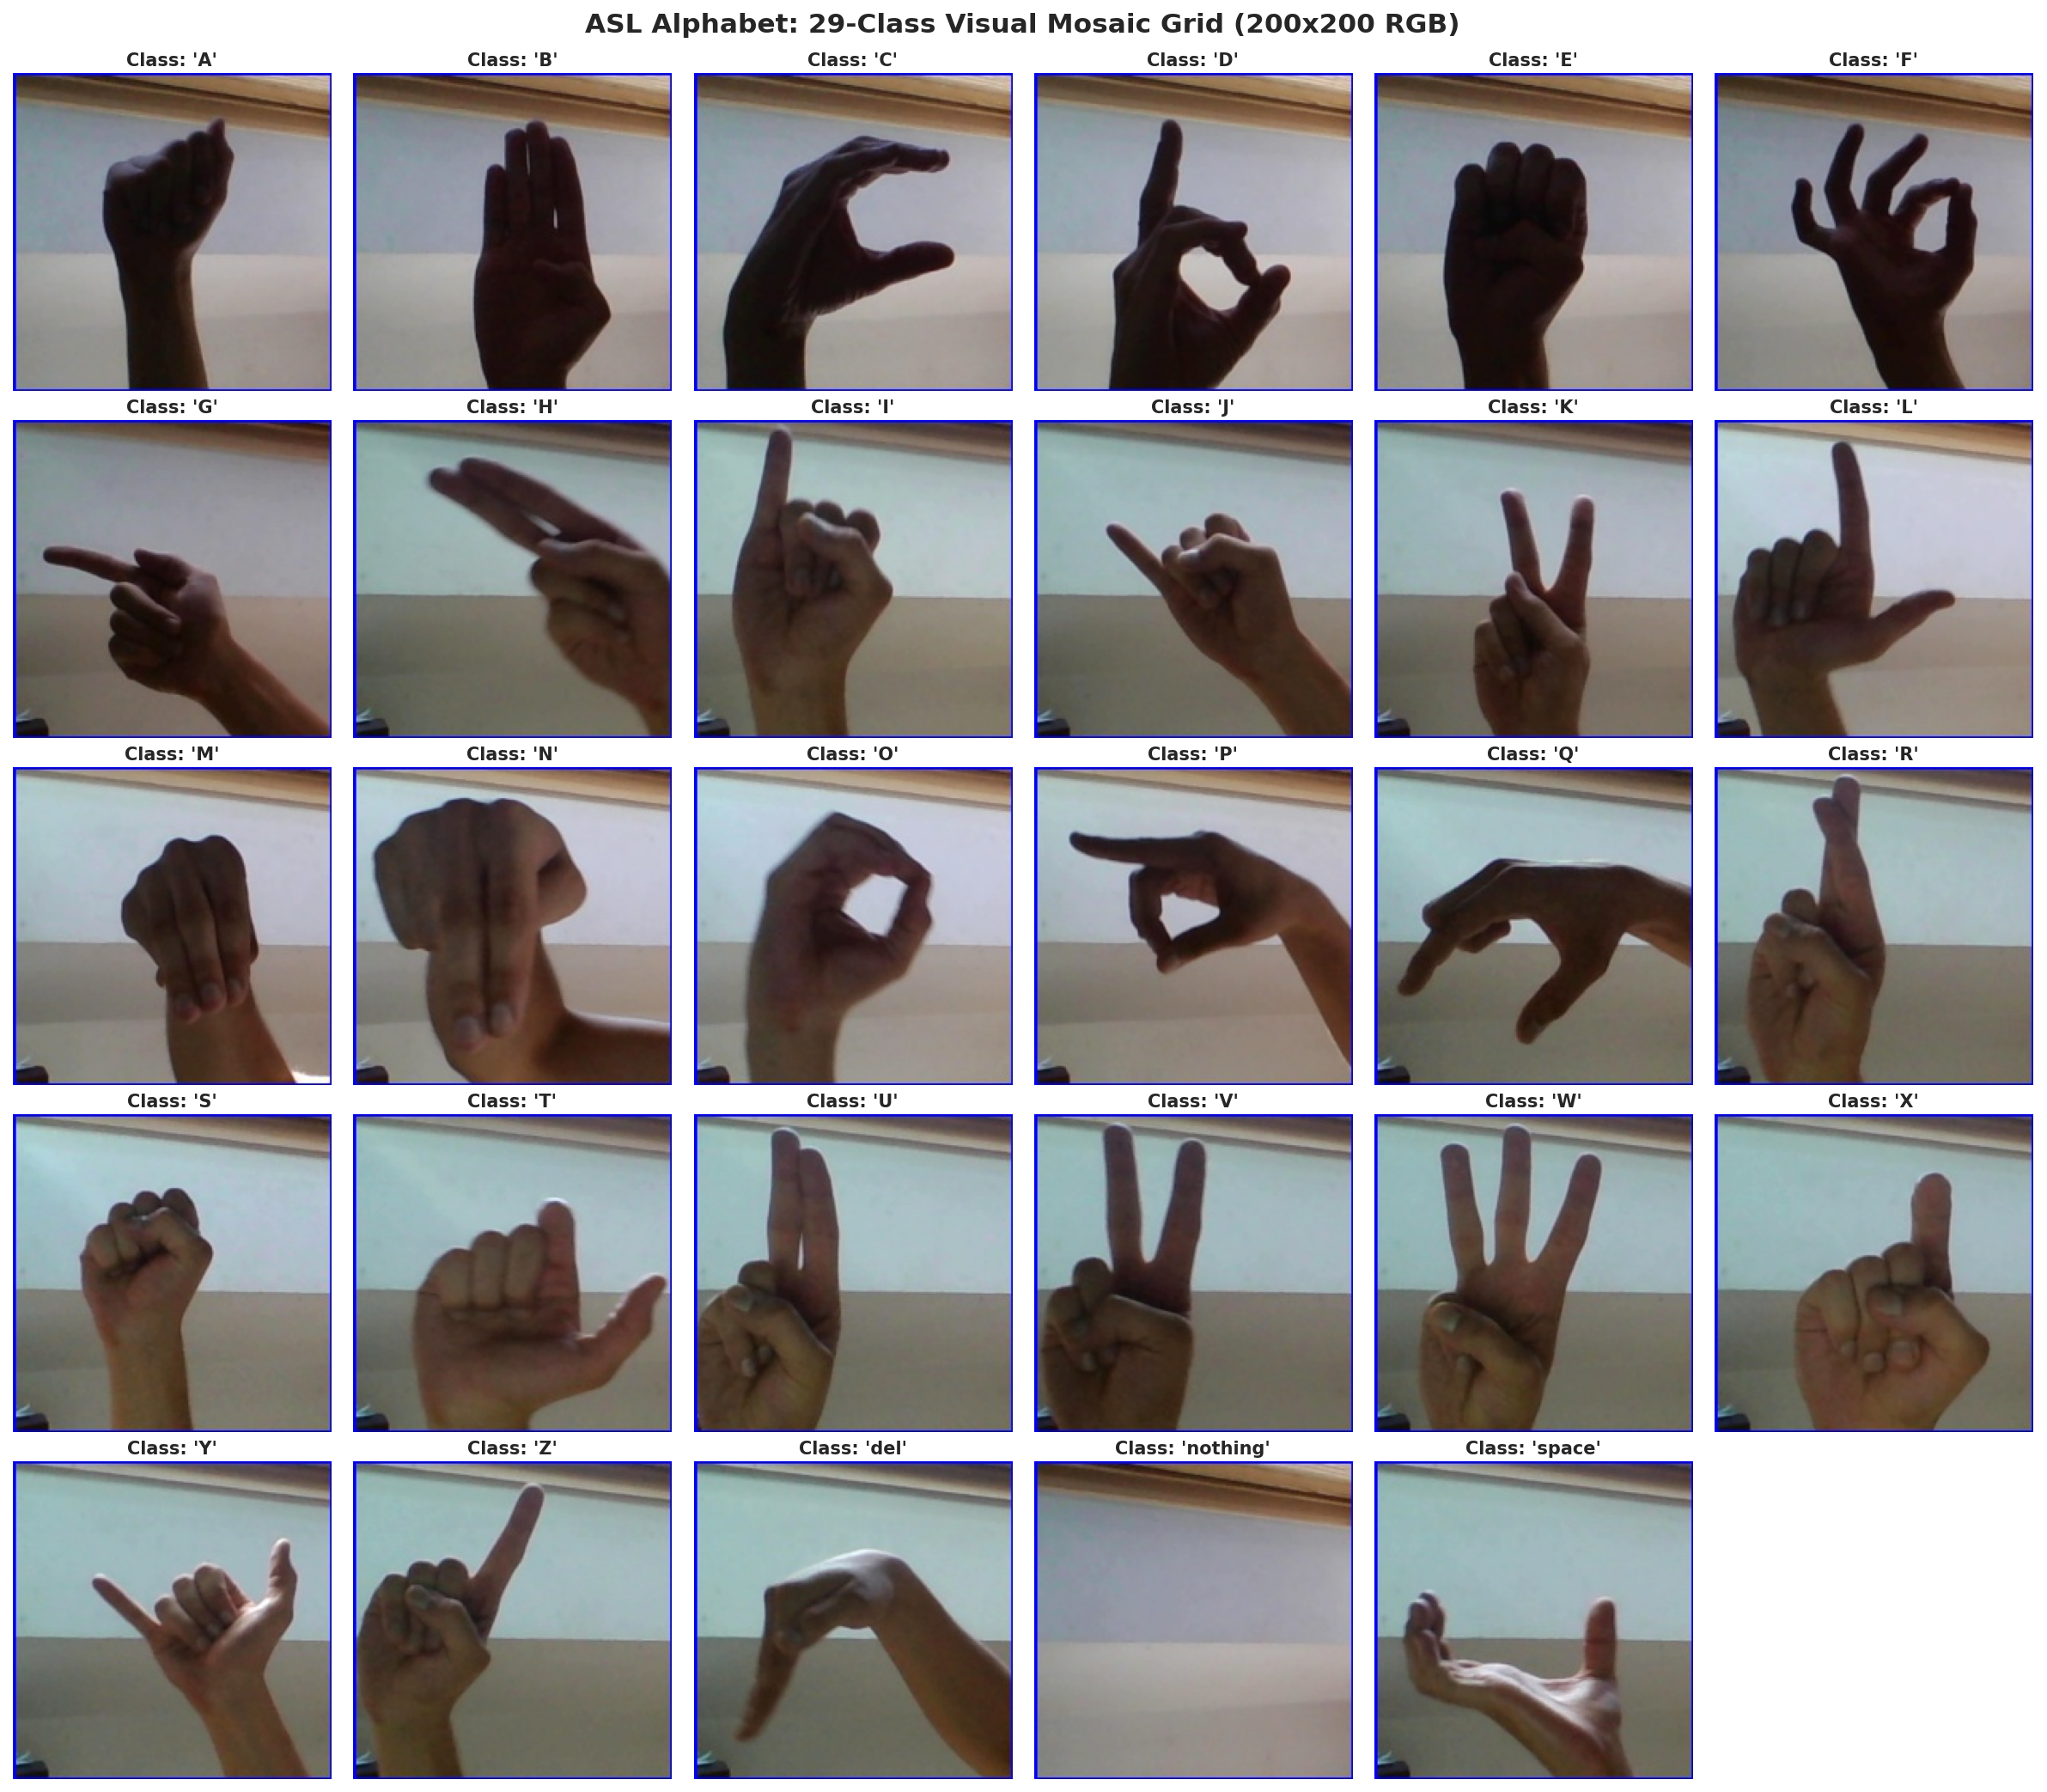

In [19]:
# Cell 5: 29-Class Visual Mosaic Grid (Reproducible First-Sample Selection)
fig, axes = plt.subplots(5, 6, figsize=(16, 14))
axes = axes.flatten()

for idx, cls_name in enumerate(CLASSES):
    files = class_file_map[cls_name]  # Pre-sorted list
    with Image.open(files[0]) as im:
        sample_img = im.copy()
    
    axes[idx].imshow(sample_img)
    axes[idx].set_title(f"Class: '{cls_name}'", fontsize=10, weight="bold", pad=4)
    axes[idx].axis("off")

# Hide unused 30th subplot slot
axes[29].axis("off")

plt.suptitle("ASL Alphabet: 29-Class Visual Mosaic Grid (200x200 RGB)", fontsize=15, weight="bold", y=0.99)
plt.tight_layout()

plt.savefig(OUTPUT_FIGS / "eda_29_class_mosaic.png", dpi=300)
plt.show()

**Cell 6 [Code]: Morphological Ambiguity Matrix (3×3)**

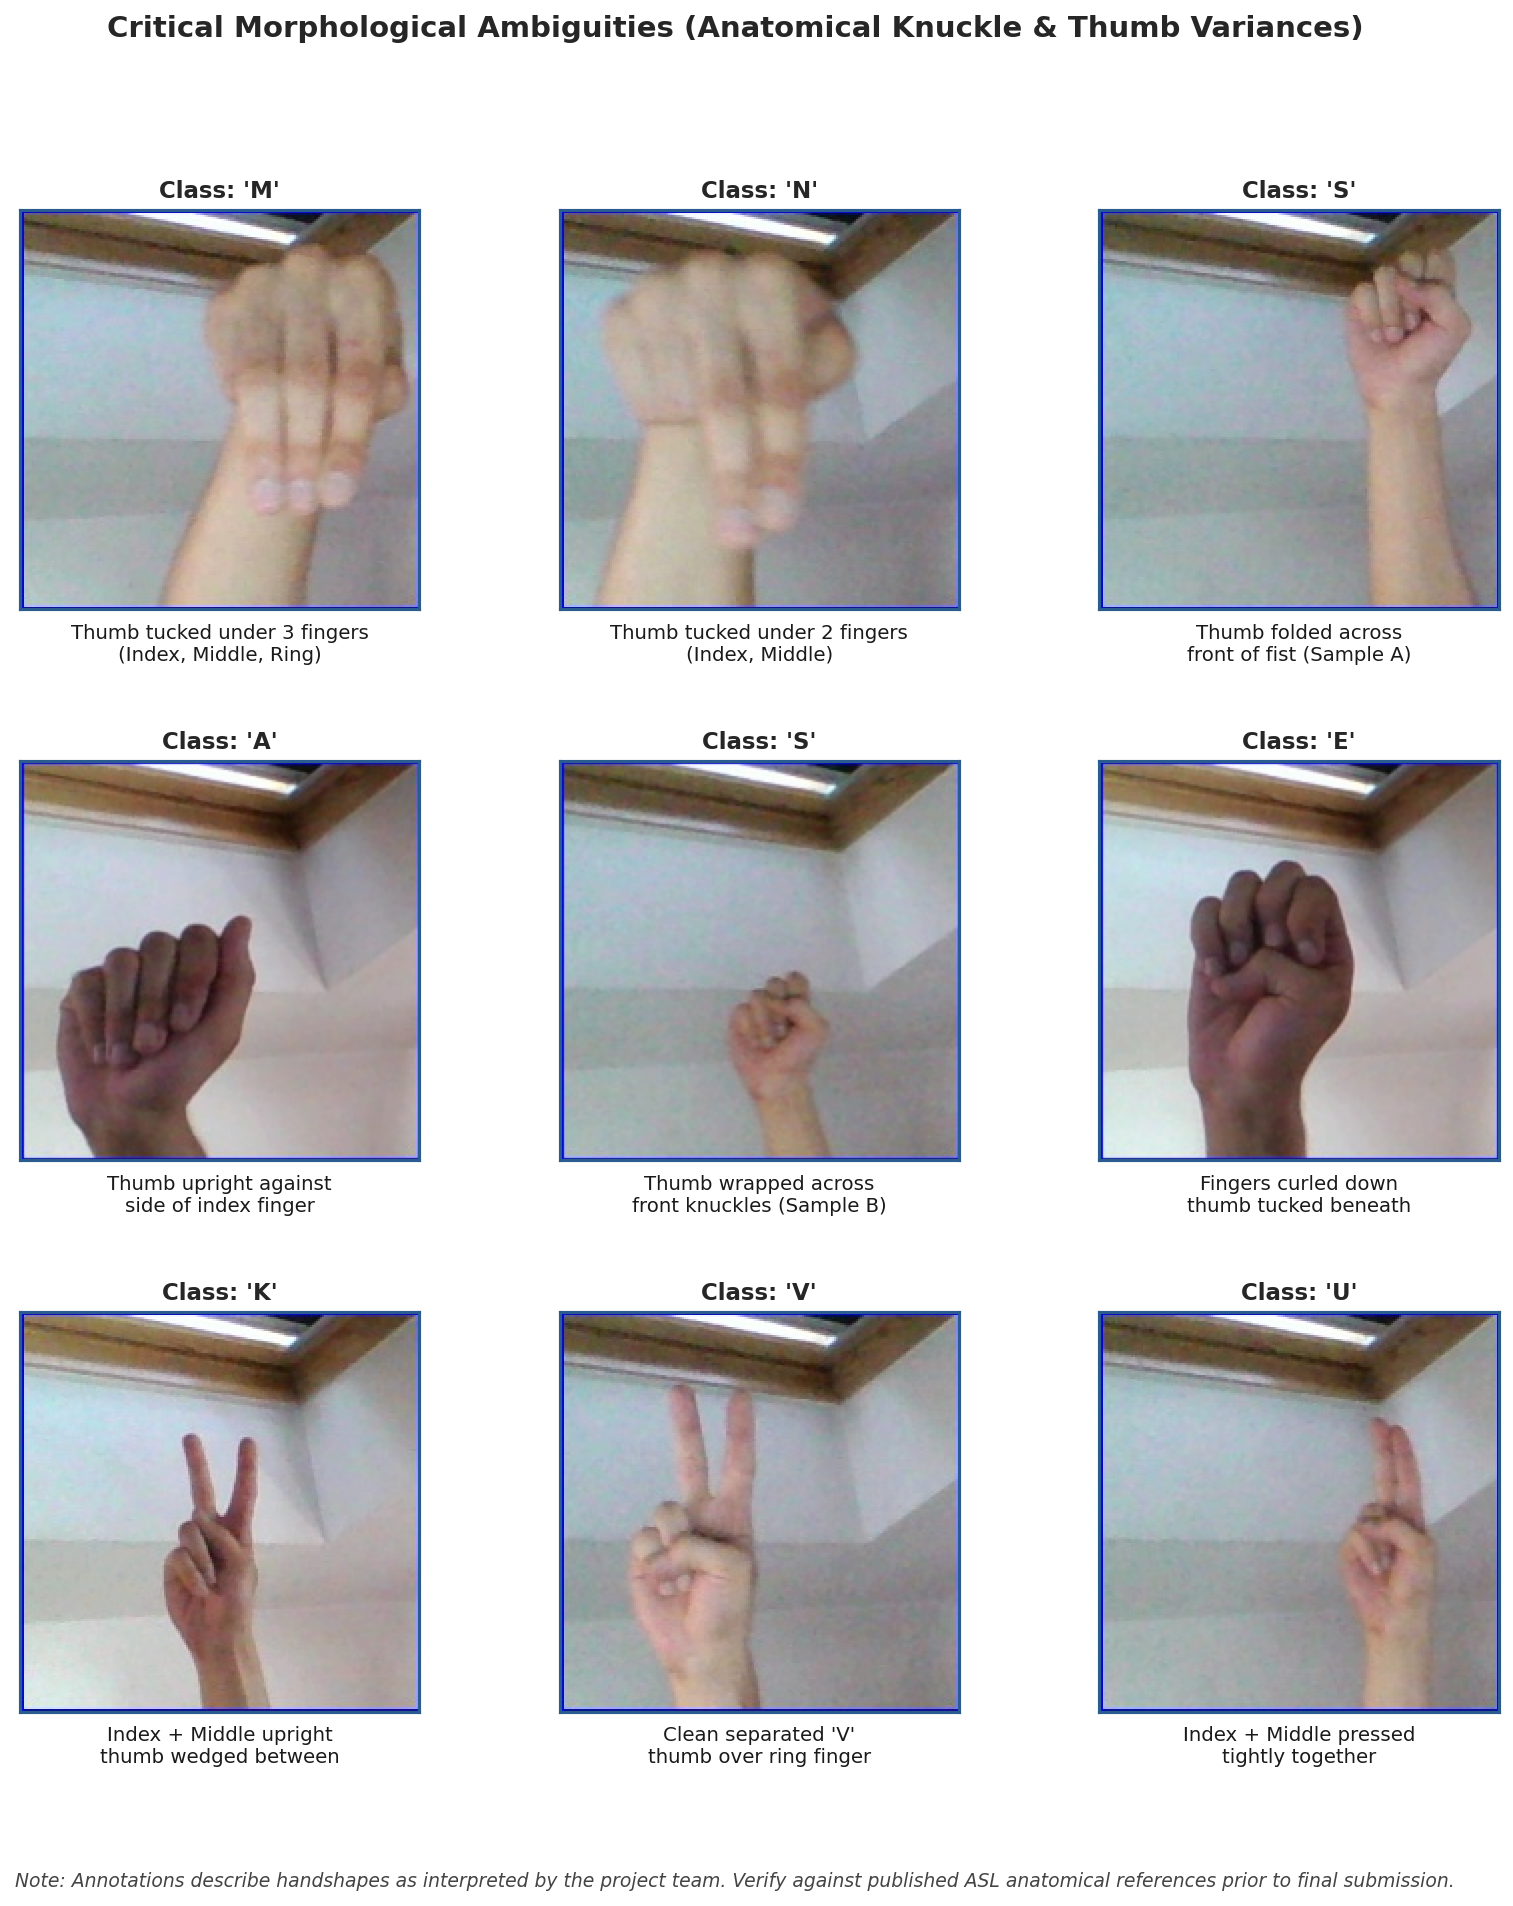

In [20]:
# Cell 6: Morphological Ambiguities Matrix (Contrast-Filtered Unique Samples)

used_image_paths = set()

def get_distinct_well_lit_sample(cls_name):
    """
    Returns (image, path) for a contrast-filtered sample not yet displayed in this figure.
    Filters by mean luminance and standard deviation (contrast).
    """
    files = class_file_map[cls_name]
    # Selected candidate indices across the class directory
    preferred_indices = [60, 220, 380, 550, 750, 950, 1200, 1500, 1800, 15, 100]
    preferred = [files[i] for i in preferred_indices if i < len(files)]
    candidates = preferred + [p for p in files if p not in preferred]
    
    for p in candidates:
        if p in used_image_paths:
            continue
        with Image.open(p) as im:
            img = im.copy()
            gray = np.asarray(im.convert("L"), dtype=np.float32)
            
        # Select samples with adequate illumination and boundary contrast
        if 70 < gray.mean() < 175 and gray.std() > 34:
            used_image_paths.add(p)
            return img, p
            
    raise RuntimeError(f"No unused, contrast-filtered sample available for class '{cls_name}'")

ambiguity_matrix = [
    # Row 1: The Fist Tuck Triplet
    {
        "row_title": "Group 1: Fist Tuck Nuance (M vs N vs S)",
        "items": [
            ("M", "Thumb tucked under 3 fingers\n(Index, Middle, Ring)"),
            ("N", "Thumb tucked under 2 fingers\n(Index, Middle)"),
            ("S", "Thumb folded across\nfront of fist (Sample A)")
        ]
    },
    # Row 2: Closed Palm & Thumb Surface Placement
    {
        "row_title": "Group 2: Thumb Surface Placement (A vs S vs E)",
        "items": [
            ("A", "Thumb upright against\nside of index finger"),
            ("S", "Thumb wrapped across\nfront knuckles (Sample B)"),
            ("E", "Fingers curled down\nthumb tucked beneath")
        ]
    },
    # Row 3: Two-Finger Upright Geometries
    {
        "row_title": "Group 3: Two-Finger Geometries (K vs V vs U)",
        "items": [
            ("K", "Index + Middle upright\nthumb wedged between"),
            ("V", "Clean separated 'V'\nthumb over ring finger"),
            ("U", "Index + Middle pressed\ntightly together")
        ]
    }
]

fig, axes = plt.subplots(3, 3, figsize=(13, 13))

for r_idx, group in enumerate(ambiguity_matrix):
    for c_idx, (cls_name, note) in enumerate(group["items"]):
        ax = axes[r_idx, c_idx]
        img, _ = get_distinct_well_lit_sample(cls_name)
        
        ax.imshow(img)
        ax.set_title(f"Class: '{cls_name}'", fontsize=11, weight="bold", pad=6)
        ax.set_xlabel(note, fontsize=9.5, labelpad=7, color="#1a1a1a")
        ax.set_xticks([])
        ax.set_yticks([])
        
        for spine in ax.spines.values():
            spine.set_edgecolor("#2b5c8f")
            spine.set_linewidth(1.5)

plt.suptitle("Critical Morphological Ambiguities (Anatomical Knuckle & Thumb Variances)", fontsize=14, weight="bold", y=0.98)
plt.subplots_adjust(hspace=0.38, wspace=0.25)

# Annotation disclaimer as mandated by peer review
fig.text(
    0.5, 0.02,
    "Note: Annotations describe handshapes as interpreted by the project team. "
    "Verify against published ASL anatomical references prior to final submission.",
    ha="center", fontsize=9, style="italic", color="#444444"
)

plt.savefig(OUTPUT_FIGS / "eda_ambiguous_pairs.png", dpi=300, bbox_inches="tight")
plt.show()

**Cell 7 [Code]: Luminance Distribution & Intra-Class Background Audit**

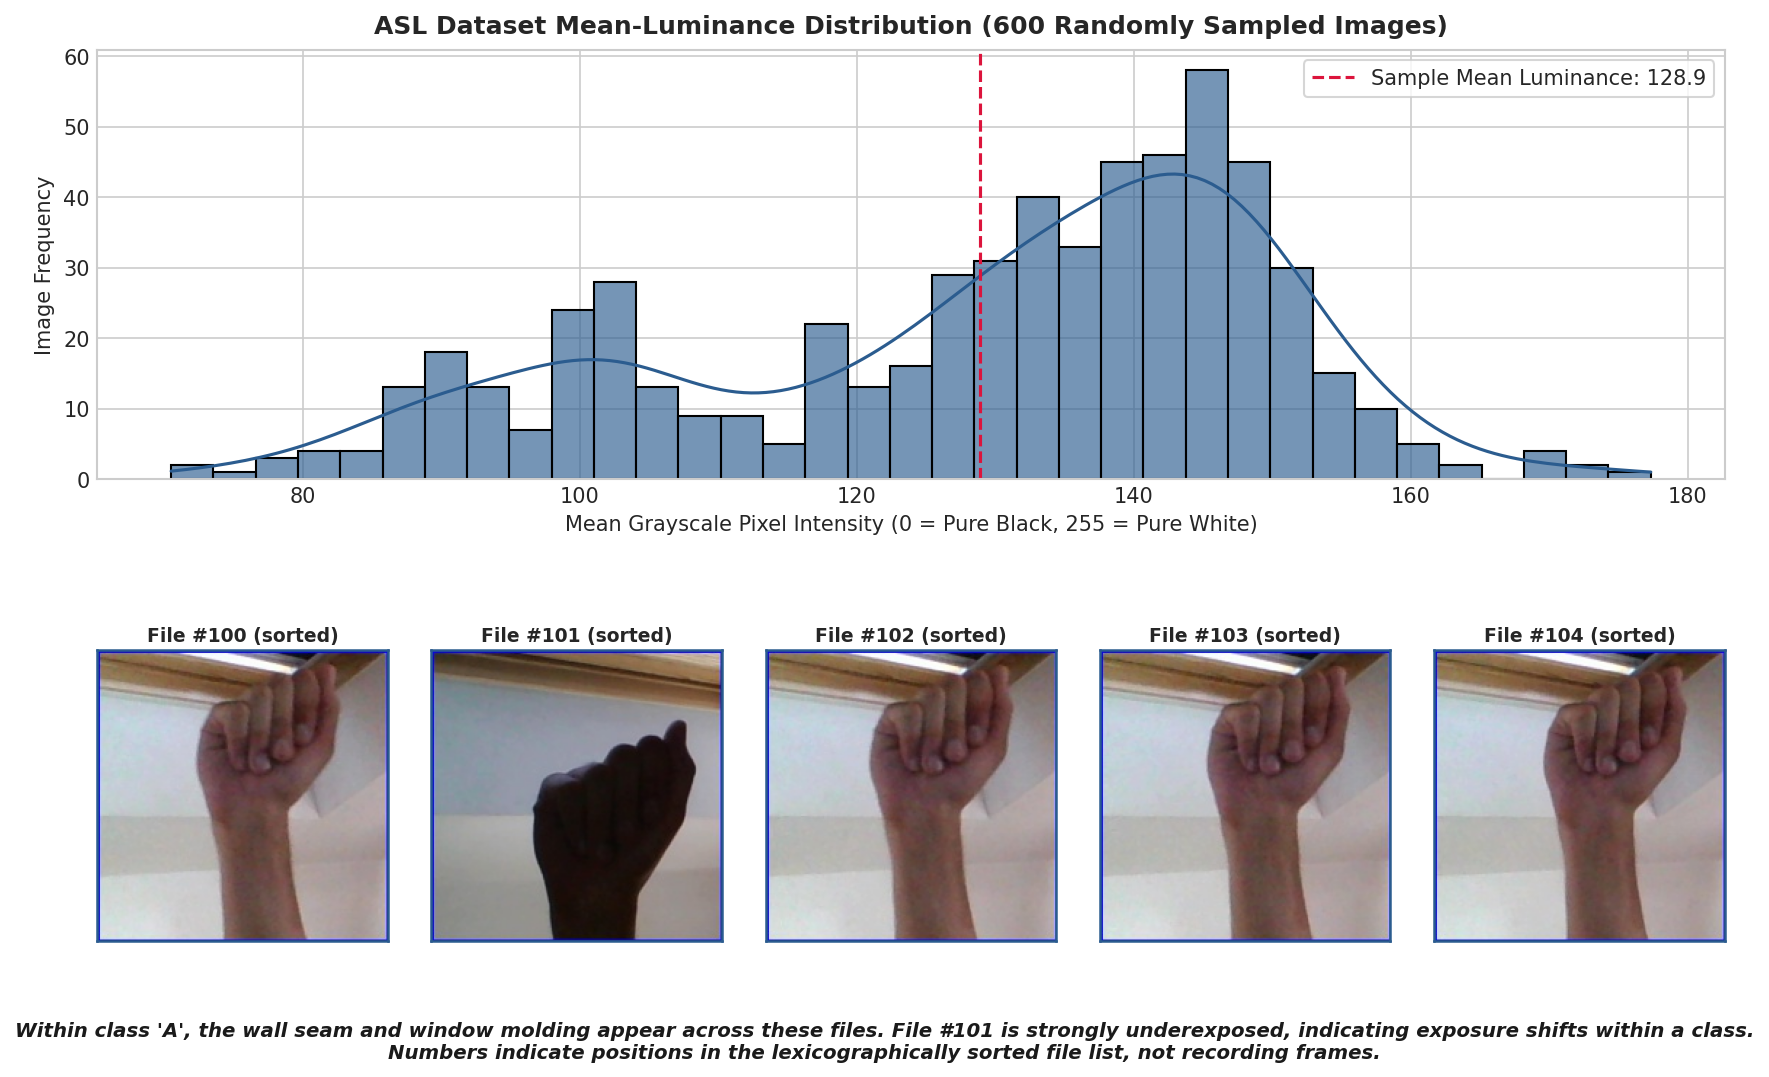

[REPRODUCIBLE METRIC] Computed Mean Luminance (N=600): 128.9


In [21]:
# Cell 7: Dataset Luminance & Intra-Class Background Inspection
import matplotlib.gridspec as gridspec

# 1. Deterministic sampling across all files
all_files = sorted(DATA_DIR.glob("*/*.jpg"))
rng_lum = random.Random(GLOBAL_SEED)
sampled_subset = rng_lum.sample(all_files, 600)

sample_brightness = []
for p in sampled_subset:
    with Image.open(p) as im:
        sample_brightness.append(float(np.asarray(im.convert("L")).mean()))

# 2. Build publication figure
fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 5, height_ratios=[1.2, 1], hspace=0.35, wspace=0.15)

# --- Top Row: Mean Luminance Histogram ---
ax_hist = fig.add_subplot(gs[0, :])
sns.histplot(sample_brightness, bins=35, kde=True, ax=ax_hist, color="#2b5c8f", edgecolor="black", alpha=0.65)
mean_lum = float(np.mean(sample_brightness))
ax_hist.axvline(mean_lum, color="crimson", linestyle="--", linewidth=1.5, label=f"Sample Mean Luminance: {mean_lum:.1f}")
ax_hist.set_title("ASL Dataset Mean-Luminance Distribution (600 Randomly Sampled Images)", fontsize=12, weight="bold", pad=8)
ax_hist.set_xlabel("Mean Grayscale Pixel Intensity (0 = Pure Black, 255 = Pure White)", fontsize=10)
ax_hist.set_ylabel("Image Frequency", fontsize=10)
ax_hist.legend(loc="upper right", frameon=True, fontsize=10)

# --- Bottom Row: 5 Sorted Samples of Class 'A' ---
class_a_files = class_file_map["A"][100:105]

for i, img_path in enumerate(class_a_files):
    ax_frame = fig.add_subplot(gs[1, i])
    with Image.open(img_path) as im:
        ax_frame.imshow(im.copy())
    ax_frame.set_title(f"File #{100+i} (sorted)", fontsize=9, weight="bold", pad=4)
    ax_frame.set_xticks([])
    ax_frame.set_yticks([])
    for spine in ax_frame.spines.values():
        spine.set_edgecolor("#2b5c8f")
        spine.set_linewidth(1.2)

fig.text(
    0.5, 0.04, 
    "Within class 'A', the wall seam and window molding appear across these files. "
    "File #101 is strongly underexposed, indicating exposure shifts within a class.\n"
    "Numbers indicate positions in the lexicographically sorted file list, not recording frames.",
    ha="center", fontsize=9.5, style="italic", weight="semibold", color="#1a1a1a"
)

plt.savefig(OUTPUT_FIGS / "eda_lighting_and_background_audit.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"[REPRODUCIBLE METRIC] Computed Mean Luminance (N=600): {mean_lum:.1f}")

**Cell 8 [Code]: Inter-Class Lighting & Background Distribution Audit**

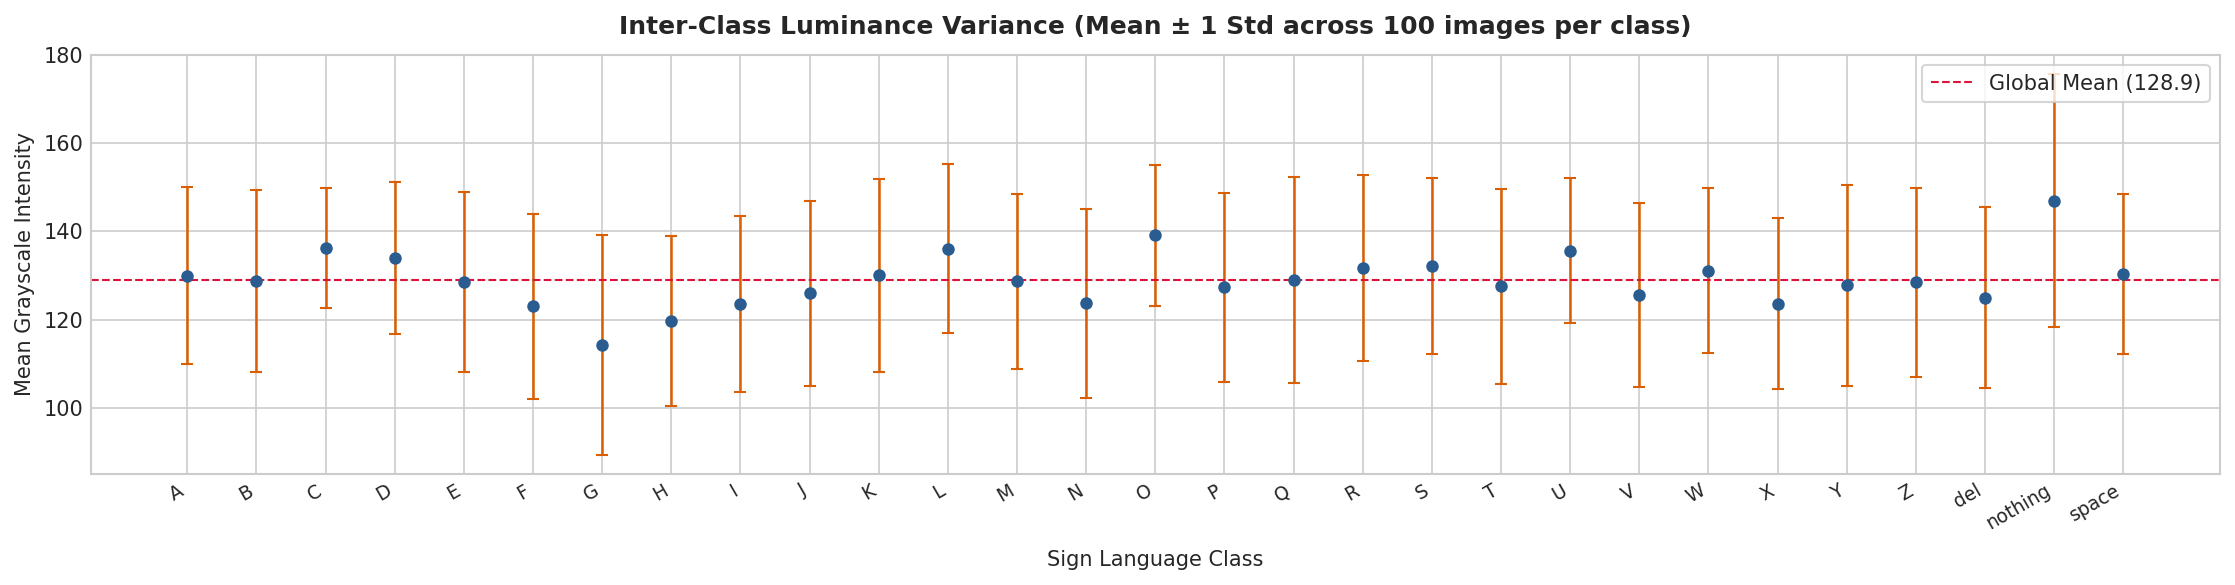

,mean,std
count,29.0,29.0
mean,129.1,20.4
std,6.3,2.8
min,114.2,13.6
25%,125.6,19.3
50%,128.7,20.5
75%,131.8,21.4
max,147.0,28.8


In [22]:
# Cell 8: Inter-Class Brightness Variation Audit
rng_class = random.Random(GLOBAL_SEED)
rows = []

for cls in CLASSES:
    files = class_file_map[cls]
    for p in rng_class.sample(files, 100):
        with Image.open(p) as im:
            rows.append((cls, float(np.asarray(im.convert("L")).mean())))

df_bright = pd.DataFrame(rows, columns=["Class", "Brightness"])
bright_stats = df_bright.groupby("Class")["Brightness"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(15, 4))
ax.errorbar(
    bright_stats["Class"], 
    bright_stats["mean"], 
    yerr=bright_stats["std"], 
    fmt='o', 
    color="#2b5c8f", 
    ecolor="#d95f02", 
    elinewidth=1.2, 
    capsize=3,
    markersize=5
)

ax.set_title("Inter-Class Luminance Variance (Mean ± 1 Std across 100 images per class)", fontsize=12, weight="bold", pad=10)
ax.set_xlabel("Sign Language Class", fontsize=10, labelpad=8)
ax.set_ylabel("Mean Grayscale Intensity", fontsize=10)
ax.axhline(mean_lum, color="crimson", linestyle="--", linewidth=1.0, label=f"Global Mean ({mean_lum:.1f})")
ax.legend(loc="upper right", frameon=True)
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()

plt.savefig(OUTPUT_FIGS / "eda_inter_class_brightness.png", dpi=300, bbox_inches="tight")
plt.show()

display(bright_stats.describe().round(1))

**Cell 9 [Code]: Intra-Class Temporal Redundancy (Near-Duplicate Analysis)**

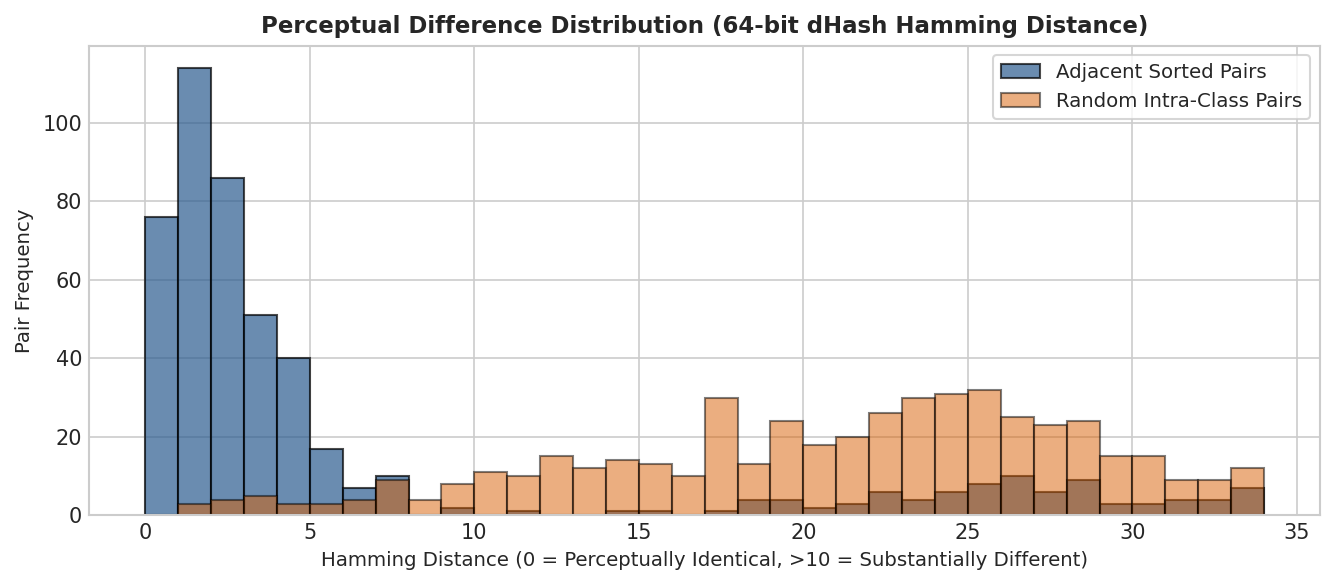

Adjacent Pairs Median Hamming Distance: 2.0
Random Pairs Median Hamming Distance   : 22.0


In [23]:
# Cell 9: Fast dHash Intra-Class Near-Duplicate Quantification
def compute_dhash(image_pil, hash_size=8):
    """Computes a 64-bit difference hash (dHash) using pure NumPy."""
    # Resize to (hash_size + 1, hash_size) and convert to grayscale
    resized = image_pil.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    arr = np.asarray(resized, dtype=np.int32)
    # Compare adjacent horizontal pixels: (W-1, H)
    diff = arr[:, 1:] > arr[:, :-1]
    return diff.flatten()

def hamming_distance(hash1, hash2):
    return int(np.count_nonzero(hash1 != hash2))

# Compute consecutive dHash distances for 500 adjacent file pairs in Class 'A'
consecutive_distances = []
class_a_samples = class_file_map["A"][:500]

hashes = []
for p in class_a_samples:
    with Image.open(p) as im:
        hashes.append(compute_dhash(im))

for i in range(len(hashes) - 1):
    consecutive_distances.append(hamming_distance(hashes[i], hashes[i+1]))

# Random baseline: 500 randomly paired images from Class 'A'
rng_hash = random.Random(GLOBAL_SEED)
random_distances = [
    hamming_distance(rng_hash.choice(hashes), rng_hash.choice(hashes))
    for _ in range(500)
]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(consecutive_distances, bins=range(0, 35), alpha=0.7, color="#2b5c8f", label="Adjacent Sorted Pairs", edgecolor="black")
ax.hist(random_distances, bins=range(0, 35), alpha=0.5, color="#d95f02", label="Random Intra-Class Pairs", edgecolor="black")

ax.set_title("Perceptual Difference Distribution (64-bit dHash Hamming Distance)", fontsize=11, weight="bold")
ax.set_xlabel("Hamming Distance (0 = Perceptually Identical, >10 = Substantially Different)", fontsize=9.5)
ax.set_ylabel("Pair Frequency", fontsize=9.5)
ax.legend(frameon=True, fontsize=9.5)
plt.tight_layout()

plt.savefig(OUTPUT_FIGS / "eda_near_duplicate_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Adjacent Pairs Median Hamming Distance: {np.median(consecutive_distances):.1f}")
print(f"Random Pairs Median Hamming Distance   : {np.median(random_distances):.1f}")

## **Cell 10: Synthesis of Exploratory Findings for System Architecture Design**

### **1. Optimization Objectives & Class Balance**

* **Empirical Prior Uniformity**: The dataset contains exactly 3,000 images per class ($N = 87,000$). Balanced class priors eliminate prior-driven bias from the cross-entropy loss objective. Individual per-class gradient vectors will still vary in magnitude based on data complexity and morphological difficulty.
* **Metric Standardization**: Macro-averaged metrics (Accuracy, Macro-Precision, Macro-Recall, Macro-F1) will treat all 29 gesture categories equally, preventing dominant classes from masking localized failures.

### **2. Illumination & Background Shortcut Learning Hypotheses**

* **Luminance Profile**: Scene mean luminance spans approximately 80 to 175 with a primary mode near 140–145 and a shoulder near 100. Because whole-image averages combine foreground hand and background pixels, foreground versus background luminance cannot be disentangled without spatial segmentation masks (addressed in Task 2.2).
* **Static Scene Elements**: Static indoor wall seams, ceiling molding, and window contours persist across sorted files within class folders. Convolutional kernels trained on uncropped images risk learning background artifacts rather than hand anatomy. Task 3.5 will empirically measure this effect by comparing models trained with and without dynamic background swapping.

### **3. Intra-Class Temporal Redundancy & Evaluation Implications**

* **Near-Duplicate Redundancy**: Perceptual hashing (64-bit dHash) reveals that adjacent sorted image pairs exhibit low median Hamming distance compared to random intra-class pairs. This indicates that the dataset contains frames extracted from continuous recording sequences.
* **Evaluation Interpretation**: While a stratified random 70/15/15 split strictly satisfies Dr. Ngan's rubric specifications (60,900 / 13,050 / 13,050 samples), the in-distribution test set score represents an optimistic upper bound. The Out-of-Distribution (OOD) benchmark (`data/external_test/`) serves as the true estimate of real-world generalization.

### **4. Fine-Grained Morphological Ambiguities**

* **Localized Morphological Differences**: Gestures in the fist tuck group (`M`, `N`, `S`), closed palm group (`A`, `E`), and two-finger upright group (`K`, `V`, `U`) differ primarily in thumb placement and knuckle flexion across a localized pixel region.
* **Architectural Justification**:
  * **Model 1 (Simple CNN)**: Sequential pooling downsamples spatial resolution, and the model is expected to show higher error rates on visually similar pairs like `M` vs `N`. This will be quantitatively evaluated using the confusion matrix in Task 4.2.
  * **Model 2 (Mini-ResNet)**: Residual identity connections ($\mathbf{x}_{l+1} = \mathcal{F}(\mathbf{x}_l) + \mathbf{x}_l$) provide uninterrupted gradient highways that ease the optimization of deeper networks, allowing the model to train more layers effectively without vanishing gradients. They do not, however, restore spatial resolution lost to downsampling layers.
  * **Model 3 (Transfer Learning)**: Channel attention mechanisms (such as Squeeze-and-Excitation in MobileNetV3) dynamically re-weight feature channels to emphasize localized knuckle boundaries while suppressing background responses.